# Day 9: Exploratory Data Analysis – Laptop Price Dataset

In Day 8 I cleaned the Kaggle laptop price dataset. Today I'm using that cleaned file to understand the data: what laptops are in it, what affects the price, and what a laptop seller could learn from it.

**Plan:** descriptive statistics → a few new columns → trends and patterns → visualizations → business insights.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

In [2]:
df = pd.read_csv("data/laptop_data_cleaned.csv")
df.head()

,brand,type,screen_size_inch,screen_resolution,cpu,ram_gb,storage,gpu,os,weight_kg,price_inr
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,71379
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,47896
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,30636
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,135195
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,96096


In [3]:
print(df.shape)
df.info()

(1243, 11)
<class 'pandas.DataFrame'>
RangeIndex: 1243 entries, 0 to 1242
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   brand              1243 non-null   str    
 1   type               1243 non-null   str    
 2   screen_size_inch   1243 non-null   float64
 3   screen_resolution  1243 non-null   str    
 4   cpu                1243 non-null   str    
 5   ram_gb             1243 non-null   int64  
 6   storage            1243 non-null   str    
 7   gpu                1243 non-null   str    
 8   os                 1243 non-null   str    
 9   weight_kg          1243 non-null   float64
 10  price_inr          1243 non-null   int64  
dtypes: float64(2), int64(2), str(7)
memory usage: 106.9 KB


1,243 laptops, 11 columns, no missing values (cleaned in Day 8).

## Descriptive statistics

### Numeric columns

In [4]:
df.describe().round(2)

,screen_size_inch,ram_gb,weight_kg,price_inr
count,1243.00,1243.00,1243.00,1243.00
mean,15.03,8.52,2.04,60604.41
std,1.43,5.59,0.68,37439.66
min,10.10,1.00,0.69,9271.00
25%,14.00,4.00,1.50,32650.50
50%,15.60,8.00,2.04,52694.00
75%,15.60,8.00,2.31,79813.00
max,18.40,64.00,4.70,324955.00


In [5]:
price = df["price_inr"]
print("Mean price:  ", round(price.mean()))
print("Median price:", round(price.median()))
print("Mode price:  ", price.mode()[0])
print("Std dev:     ", round(price.std()))
print("Range:       ", price.min(), "to", price.max())
print("Skewness:    ", round(price.skew(), 2))

Mean price:   60604
Median price: 52694
Mode price:   58555
Std dev:      37440
Range:        9271 to 324955
Skewness:     1.52


The mean (≈60.6k) is higher than the median (≈52.7k) and skewness is positive, so the price is **right skewed**: most laptops are in the lower-mid range and a few very expensive ones pull the mean up. Because of this I'll mostly compare **median** prices below.

### Categorical columns

In [6]:
df.describe(exclude="number")

,brand,type,screen_resolution,cpu,storage,gpu,os
count,1243,1243,1243,1243,1243,1243,1243
unique,19,6,40,118,39,110,8
top,Lenovo,Notebook,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,256GB SSD,Intel HD Graphics 620,Windows 10
freq,282,688,492,183,401,269,1021


In [7]:
df["brand"].value_counts()

brand
Lenovo       282
Dell         280
HP           260
Asus         149
Acer         101
MSI           53
Toshiba       47
Apple         21
Samsung        9
Razer          7
Mediacom       7
Microsoft      6
Xiaomi         4
Vero           4
Chuwi          3
Google         3
LG             3
Huawei         2
Fujitsu        2
Name: count, dtype: int64

In [8]:
df["type"].value_counts(normalize=True).mul(100).round(1)

type
Notebook              55.3
Gaming                16.3
Ultrabook             15.2
2 in 1 Convertible     9.0
Workstation            2.3
Netbook                1.8
Name: proportion, dtype: float64

In [9]:
df["os"].value_counts(normalize=True).mul(100).round(1)

os
Windows 10      82.1
No OS            5.1
Linux            4.6
Windows 7        3.6
Chrome OS        2.2
macOS            1.7
Windows 10 S     0.6
Android          0.1
Name: proportion, dtype: float64

In [10]:
df["ram_gb"].value_counts().sort_index()

ram_gb
1       1
2      16
4     358
6      34
8     595
12     25
16    191
24      3
32     17
64      3
Name: count, dtype: int64

Quick notes:
- Lenovo, Dell and HP together make up most of the data.
- More than half the laptops are regular Notebooks.
- Windows 10 is on ~82% of laptops.
- 8 GB is the most common RAM, then 4 GB.

## Creating a few useful columns

The `cpu`, `gpu`, `storage` and `screen_resolution` columns are long text, so it's hard to compare them directly. I'll pull out the useful parts.

In [11]:
df["cpu"].sample(5, random_state=3)

648    Intel Core i7 7700HQ 2.8GHz
539     Intel Core i5 7200U 2.5GHz
505    Intel Core i7 7700HQ 2.8GHz
874     Intel Core i7 7500U 2.7GHz
946    Intel Core i7 6700HQ 2.6GHz
Name: cpu, dtype: str

In [12]:
df["cpu_series"] = df["cpu"].str.extract(r"(Core i\d|Celeron|Pentium|Atom|Xeon|Ryzen|Core M)")[0].fillna("AMD A-series / other")
df["gpu_brand"] = df["gpu"].str.split().str[0]
df["has_ssd"] = df["storage"].str.contains("SSD")
df["touchscreen"] = df["screen_resolution"].str.contains("Touchscreen")
df["ips_panel"] = df["screen_resolution"].str.contains("IPS")
df["resolution_width"] = df["screen_resolution"].str.extract(r"(\d+)x\d+")[0].astype(int)

df[["cpu_series", "gpu_brand", "has_ssd", "touchscreen", "ips_panel", "resolution_width"]].head()

,cpu_series,gpu_brand,has_ssd,touchscreen,ips_panel,resolution_width
0,Core i5,Intel,True,False,True,2560
1,Core i5,Intel,False,False,False,1440
2,Core i5,Intel,True,False,False,1920
3,Core i7,AMD,True,False,True,2880
4,Core i5,Intel,True,False,True,2560


In [13]:
df["cpu_series"].value_counts()

cpu_series
Core i7                 502
Core i5                 410
Core i3                 132
Celeron                  76
AMD A-series / other     57
Pentium                  30
Core M                   17
Atom                     11
Ryzen                     4
Xeon                      4
Name: count, dtype: int64

## Trends and patterns

### What's related to price? (correlation)

In [14]:
df[["price_inr", "ram_gb", "resolution_width", "weight_kg", "screen_size_inch"]].corr()["price_inr"].sort_values(ascending=False).round(2)

price_inr           1.00
ram_gb              0.68
resolution_width    0.55
weight_kg           0.22
screen_size_inch    0.06
Name: price_inr, dtype: float64

RAM has the strongest relation with price (0.68), then screen resolution (0.55). Weight and screen size barely matter. This surprised me a bit; I expected bigger screens to cost more, but cheap 15.6" notebooks are very common.

### Median price by different features

In [15]:
df.groupby("type")["price_inr"].agg(["count", "median"]).sort_values("median")

,count,median
type,,
Netbook,22,19713.5
Notebook,688,37109.5
2 in 1 Convertible,112,63883.0
Gaming,203,79215.0
Ultrabook,189,79920.0
Workstation,29,110018.0


In [16]:
df.groupby("ram_gb")["price_inr"].agg(["count", "median"])

,count,median
ram_gb,,
1,1,53227.0
2,16,13160.5
4,358,26557.0
6,34,31344.0
8,595,59462.0
12,25,66547.0
16,191,100752.0
24,3,126913.0
32,17,167692.0


In [17]:
df.groupby("has_ssd")["price_inr"].agg(["count", "median"])

,count,median
has_ssd,,
False,427,30103.0
True,816,67479.0


In [18]:
df.groupby("cpu_series")["price_inr"].agg(["count", "median"]).sort_values("median")

,count,median
cpu_series,,
Atom,11,13267.0
Celeron,76,16262.5
Pentium,30,21111.5
AMD A-series / other,57,24029.0
Core i3,132,26587.0
Core i5,410,51096.0
Core M,17,68145.0
Core i7,502,79114.5
Ryzen,4,86420.5


In [19]:
df.groupby("gpu_brand")["price_inr"].agg(["count", "median"]).sort_values("median")

,count,median
gpu_brand,,
AMD,169,35112.0
ARM,1,35112.0
Intel,684,49550.5
Nvidia,389,66547.0


In [20]:
df.groupby("touchscreen")["price_inr"].median()

touchscreen
False    50296.5
True     74539.0
Name: price_inr, dtype: float64

In [21]:
# brands with at least 20 laptops, so the median means something
brand_stats = df.groupby("brand")["price_inr"].agg(["count", "median"])
brand_stats = brand_stats[brand_stats["count"] >= 20].sort_values("median")
brand_stats

,count,median
brand,,
Acer,101,30476.0
Lenovo,282,47899.0
HP,260,52161.0
Dell,280,52987.0
Asus,149,55939.0
Toshiba,47,64469.0
Apple,21,71379.0
MSI,53,85195.0


Patterns I can see:
- Price climbs steadily with RAM: 4 GB ≈ 26.6k → 8 GB ≈ 59.5k → 16 GB ≈ 1 lakh.
- SSD laptops have a median price more than 2x higher than laptops without an SSD.
- CPU matters a lot: Core i3 ≈ 26.6k, i5 ≈ 51k, i7 ≈ 79k.
- Workstations, Ultrabooks and Gaming laptops are the premium types; Notebooks and Netbooks are budget.
- Acer is clearly the budget brand, MSI and Apple are at the top.

## Visualizations

### 1. Price distribution

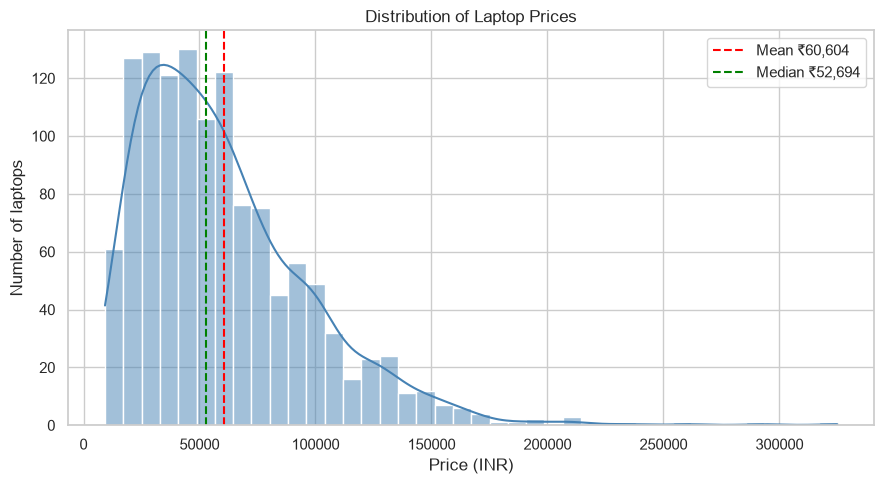

In [22]:
plt.figure()
sns.histplot(df["price_inr"], bins=40, kde=True, color="steelblue")
plt.axvline(price.mean(), color="red", linestyle="--", label=f"Mean ₹{price.mean():,.0f}")
plt.axvline(price.median(), color="green", linestyle="--", label=f"Median ₹{price.median():,.0f}")
plt.title("Distribution of Laptop Prices")
plt.xlabel("Price (INR)")
plt.ylabel("Number of laptops")
plt.legend()
plt.tight_layout()
plt.savefig("charts/1_price_distribution.png", dpi=120)
plt.show()

Most laptops are between ₹20k and ₹80k. The long tail on the right is the expensive gaming laptops and workstations.

### 2. Median price by laptop type

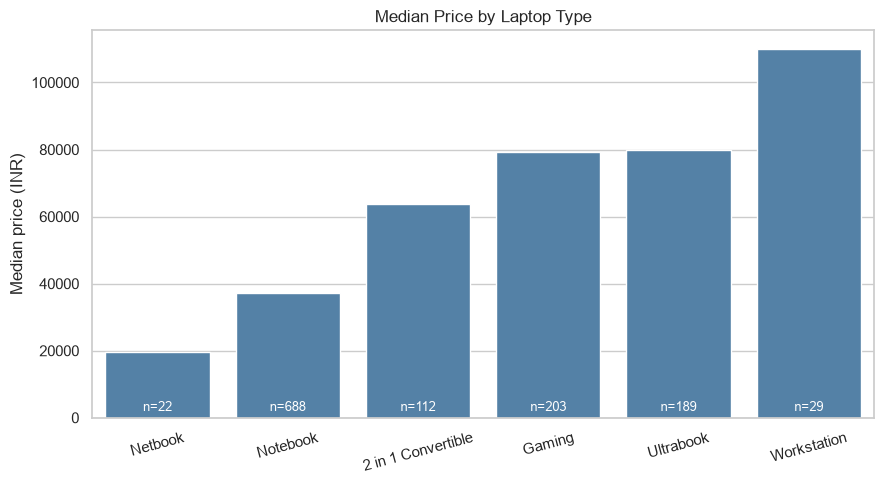

In [23]:
type_order = df.groupby("type")["price_inr"].median().sort_values().index
type_counts = df["type"].value_counts()

plt.figure()
ax = sns.barplot(data=df, x="type", y="price_inr", order=type_order, estimator=np.median, errorbar=None, color="steelblue")
for i, t in enumerate(type_order):
    ax.text(i, 2000, f"n={type_counts[t]}", ha="center", color="white", fontsize=9)
plt.title("Median Price by Laptop Type")
plt.xlabel("")
plt.ylabel("Median price (INR)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("charts/2_price_by_type.png", dpi=120)
plt.show()

### 3. RAM vs price

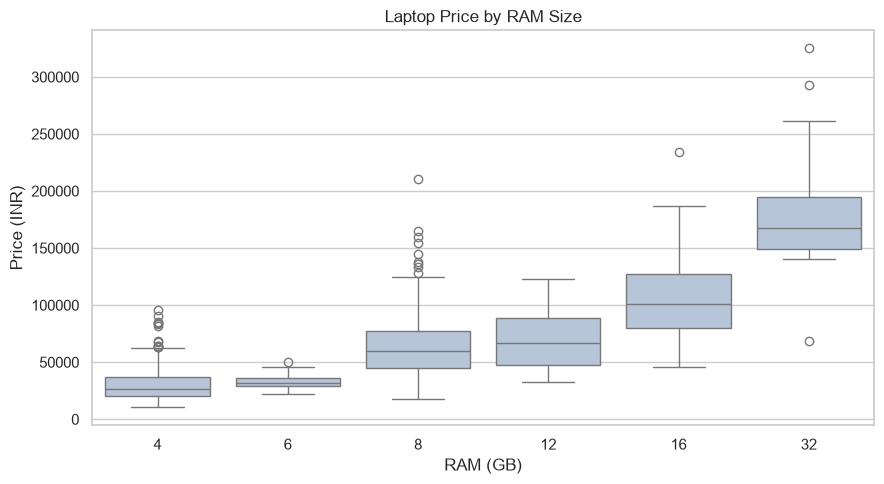

In [24]:
plt.figure()
ram_main = df[df["ram_gb"].isin([4, 6, 8, 12, 16, 32])]  # leaving out RAM sizes with only 1-3 laptops
sns.boxplot(data=ram_main, x="ram_gb", y="price_inr", color="lightsteelblue")
plt.title("Laptop Price by RAM Size")
plt.xlabel("RAM (GB)")
plt.ylabel("Price (INR)")
plt.tight_layout()
plt.savefig("charts/3_price_by_ram.png", dpi=120)
plt.show()

Clear upward trend: every jump in RAM moves the whole box up. 16 GB and 32 GB laptops are almost all above ₹60k.

### 4. SSD vs no SSD, and CPU series

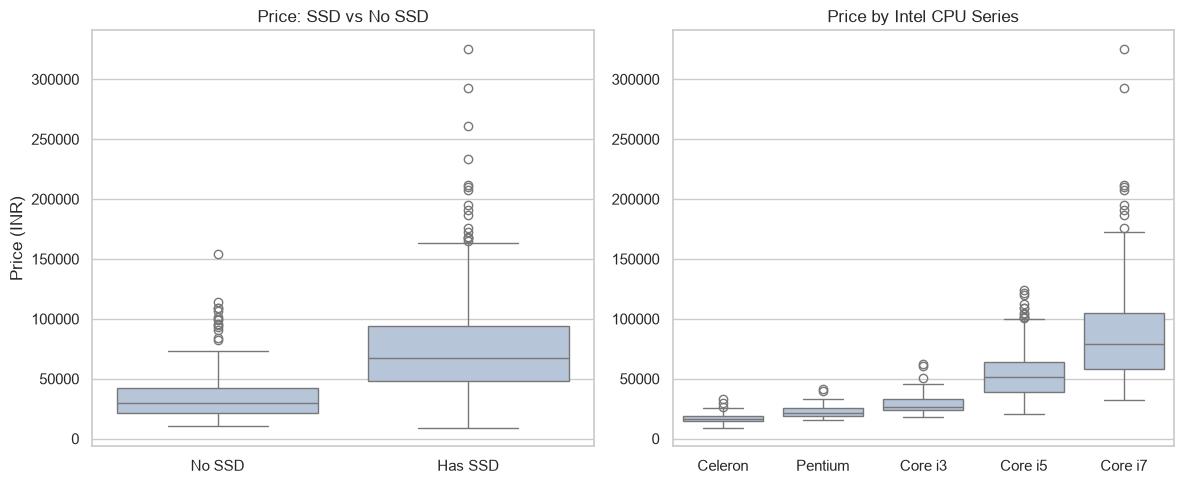

In [25]:
cpu_order = ["Celeron", "Pentium", "Core i3", "Core i5", "Core i7"]
cpu_main = df[df["cpu_series"].isin(cpu_order)]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=df, x="has_ssd", y="price_inr", ax=axes[0], color="lightsteelblue")
axes[0].set_xticks([0, 1], ["No SSD", "Has SSD"])
axes[0].set_title("Price: SSD vs No SSD")
axes[0].set_xlabel("")
axes[0].set_ylabel("Price (INR)")

sns.boxplot(data=cpu_main, x="cpu_series", y="price_inr", order=cpu_order, ax=axes[1], color="lightsteelblue")
axes[1].set_title("Price by Intel CPU Series")
axes[1].set_xlabel("")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig("charts/4_ssd_and_cpu.png", dpi=120)
plt.show()

### 5. Brands: number of laptops vs median price

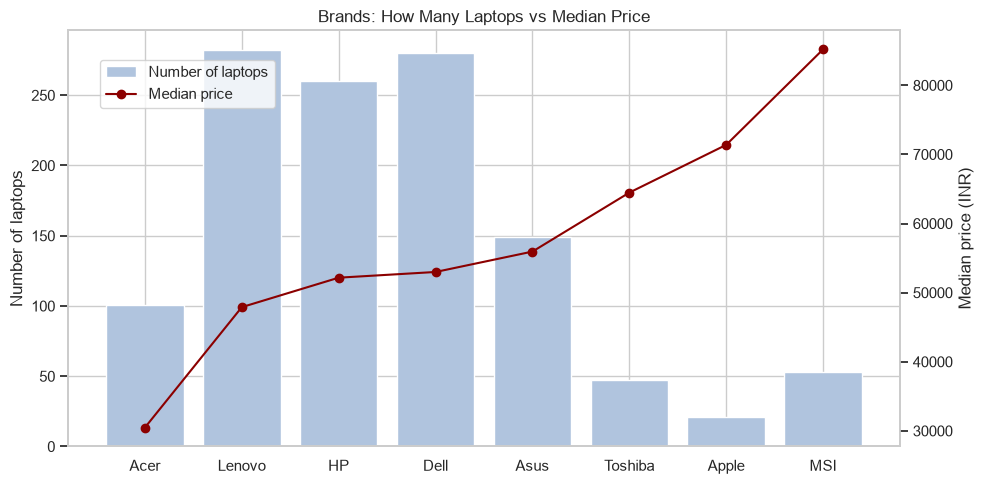

In [26]:
fig, ax1 = plt.subplots(figsize=(10, 5))
brands = brand_stats.index
ax1.bar(brands, brand_stats["count"], color="lightsteelblue", label="Number of laptops")
ax1.set_ylabel("Number of laptops")

ax2 = ax1.twinx()
ax2.plot(brands, brand_stats["median"], color="darkred", marker="o", label="Median price")
ax2.set_ylabel("Median price (INR)")
ax2.grid(False)

ax1.set_title("Brands: How Many Laptops vs Median Price")
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.88))
plt.tight_layout()
plt.savefig("charts/5_brands.png", dpi=120)
plt.show()

Lenovo, Dell and HP have the most laptops and sit in the middle on price. Acer is cheap, and the brands with fewer models (Toshiba, Apple, MSI) are the expensive ones.

## Business insights

**1. RAM is the biggest driver of price.**
RAM has the highest correlation with price (0.68). The median price goes from about ₹26.6k for 4 GB to ₹59.5k for 8 GB and about ₹1 lakh for 16 GB. 8 GB is also the most common configuration (~48% of laptops), so it's the main mid-range sweet spot. A seller can offer RAM upgrades as an easy way to move customers to a higher price point.

**2. SSD is now expected in mid and high-end laptops.**
About 66% of laptops have an SSD, and their median price (~₹67.5k) is more than double that of laptops without one (~₹30k). Laptops without an SSD are basically the budget segment. For anything above budget, SSD should be standard.

**3. The market is split into a large budget segment and a premium segment.**
Notebooks are ~55% of all laptops with a median of ~₹37k, while Gaming, Ultrabook and Workstation laptops have medians of ₹79k–₹1.1 lakh. Notebooks drive volume, the premium types drive revenue per sale. A store should stock plenty of notebooks but promote gaming and ultrabooks for higher margins.

**4. Brands are clearly positioned at different price levels.**
Lenovo, Dell and HP together have ~66% of the laptops and are in the mid range (₹48k–₹53k median). Acer is the budget option (~₹30k), while MSI (~₹85k) and Apple (~₹71k) are premium. This helps in targeting: Acer for students on a budget, MSI for gamers, Apple and ultrabooks for professionals.

**5. Processor tier sets the price band.**
Median price: Core i3 ≈ ₹26.6k, Core i5 ≈ ₹51k, Core i7 ≈ ₹79k. Core i5 and i7 together are about 73% of laptops, so most of the market is mid to high performance. Celeron/Pentium laptops are a small, very cheap segment (under ₹22k median).

**Extra:** Windows 10 is on ~82% of laptops, and ~5% ship with no OS (these are cheaper laptops where the buyer installs the OS). Touchscreen laptops have a median ~₹74.5k vs ~₹50k without, so touch is a premium feature.

## Conclusion

The price of a laptop in this dataset mostly comes from its specs: RAM, SSD, CPU tier and laptop type. Screen size and weight have very little effect. Brand also matters because each brand targets a different price segment. These insights can help a laptop seller decide what to stock, how to price upgrades, and which customers to target with which brand.

*Note: this dataset is a snapshot of laptop listings, so the numbers describe this data and not the full market.*